# Superstore Retail Sales | Exploratory Data Analysis
**Objective:** Clean and profile retail transactions; analyze purchase volume, seasonality, category/region/segment performance, and discount sensitivity.

**Data source:** [Datheon Superstore Sales CSV](https://www.datheon.in/datasets/superstore_sales.csv)

> **Reproducibility note:** The dataset was not accessible in the notebook-generation environment. Run all cells with internet access, or place `superstore_sales.csv` beside this notebook. Findings below are calculated from the actual dataset when run, not assumed in advance.

## 1. Setup and data import

In [1]:
# If needed, uncomment:
# %pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
DATA_URL = "https://www.datheon.in/datasets/superstore_sales.csv"
local_file = Path("superstore_sales.csv")
try:
    df_raw = pd.read_csv(local_file) if local_file.exists() else pd.read_csv(DATA_URL)
except Exception as exc:
    raise RuntimeError("Could not load CSV. Download it from the provided link and save as superstore_sales.csv next to this notebook.") from exc
print(f"Loaded {len(df_raw):,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())

Loaded 10,800 rows × 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


## 2. Standardize columns, audit missing values and duplicates

Available columns: ['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit']


,dtype,missing_n,missing_pct,unique_n
postal_code,float64,817,7.56,630
ship_mode,object,806,7.46,4
ship_date,object,806,7.46,1334
customer_id,object,806,7.46,793
order_date,object,806,7.46,1236
product_id,object,806,7.46,1862
category,object,806,7.46,3
segment,object,806,7.46,3
customer_name,object,806,7.46,793
country,object,806,7.46,1


Exact duplicate rows: 504


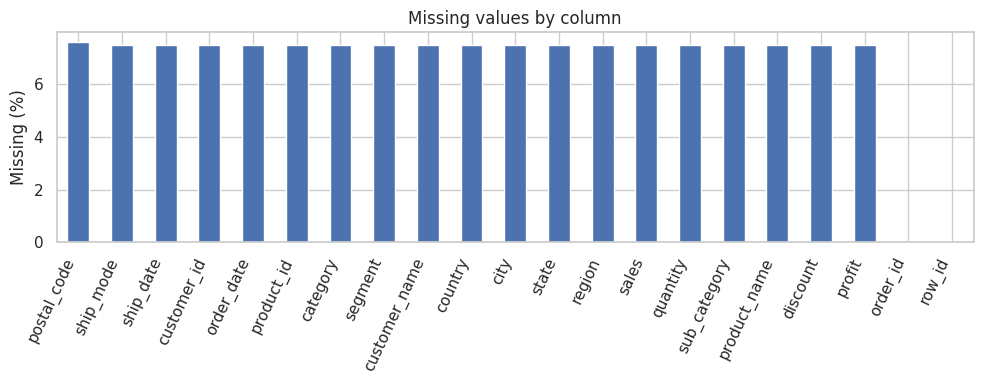

In [2]:
df = df_raw.copy()
df.columns = (df.columns.astype(str).str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
# Common variants across Superstore datasets
aliases = {"order_date":"order_date", "sales":"sales", "profit":"profit",
           "discount":"discount", "category":"category", "region":"region",
           "segment":"segment", "customer_id":"customer_id",
           "order_id":"order_id", "quantity":"quantity", "sub_category":"sub_category"}
print("Available columns:", df.columns.tolist())
required = ["order_date", "sales", "profit", "discount", "category", "region", "segment"]
missing_required = [x for x in required if x not in df.columns]
if missing_required:
    raise ValueError(f"Dataset missing required columns: {missing_required}. Check source schema before continuing.")
profile = pd.DataFrame({"dtype":df.dtypes.astype(str), "missing_n":df.isna().sum(),
                        "missing_pct":df.isna().mean().mul(100).round(2),
                        "unique_n":df.nunique(dropna=True)})
display(profile.sort_values("missing_pct", ascending=False))
print("Exact duplicate rows:", df.duplicated().sum())
fig, ax = plt.subplots(figsize=(10,4))
profile.sort_values("missing_pct", ascending=False).missing_pct.plot.bar(ax=ax)
ax.set(title="Missing values by column", ylabel="Missing (%)", xlabel="")
plt.xticks(rotation=65, ha="right"); plt.tight_layout(); plt.show()

### Cleaning decisions
- Remove exact duplicate records only (repeat products within the same order can be legitimate).
- Coerce dates and financial columns to appropriate types; drop rows without essential date, sales, or profit values.
- Keep missing discount as **unknown**, rather than assuming 0%; omit those rows from discount-specific analysis.
- Label missing category, region, or segment as `Unknown` to preserve financial totals; exclude unknown groups when interpreting segment-specific comparisons.
- Interpret correlation as association, not proof that discounting caused profit changes.

In [3]:
original_rows = len(df)
df = df.drop_duplicates().copy()
for col in ["sales", "profit", "discount", "quantity"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(r"[$,% ,]", "", regex=True), errors="coerce")
# Parse dates (supports common US Superstore dates such as 11/8/2016)
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
if df["order_date"].isna().mean() > 0.25:
    df["order_date"] = pd.to_datetime(df_raw.loc[df.index, next(c for c in df_raw if c.strip().lower().replace(' ','_')=='order_date')], errors="coerce", dayfirst=True)
for col in ["category", "region", "segment"]:
    df[col] = df[col].astype("string").str.strip().fillna("Unknown").replace("", "Unknown")
df = df.dropna(subset=["order_date", "sales", "profit"]).copy()
# Normalize discount expressed as percent points if necessary
if df["discount"].dropna().gt(1).any():
    if df["discount"].dropna().between(0,100).all():
        df["discount"] /= 100
    else:
        print("Warning: unexpected discount values; review before interpreting.")
df["year_month"] = df["order_date"].dt.to_period("M")
df["month"] = df["order_date"].dt.month
df["year"] = df["order_date"].dt.year
df["profit_margin"] = np.where(df["sales"] != 0, df["profit"] / df["sales"], np.nan)
print(f"Removed {original_rows-len(df):,} duplicate/incomplete rows; retained {len(df):,} rows")
print("Remaining unknown discounts:", df["discount"].isna().sum())
display(df.head())

Removed 806 duplicate/incomplete rows; retained 9,994 rows
Remaining unknown discounts: 0


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,year_month,month,year,profit_margin
0,1,CA-2017-152156,2017-11-08,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2017-11,11,2017,0.1600
1,2,CA-2017-152156,2017-11-08,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2017-11,11,2017,0.3000
2,3,CA-2017-138688,2017-06-12,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2017-06,6,2017,0.4700
3,4,US-2016-108966,2016-10-11,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2016-10,10,2016,-0.4000
4,5,US-2016-108966,2016-10-11,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2016-10,10,2016,0.1125


## 3. Overall commercial performance and customer purchase volume

Sales: $2,297,200.86 | Profit: $286,397.02 | Margin: 12.5%
Orders: 5,009 | Average order sales: $458.61


,sales,profit,line_items,orders
customer_id,,,,
SM-20320,25043.050,-1980.7393,15,5
TC-20980,19052.218,8981.3239,12,5
RB-19360,15117.339,6976.0959,18,6
TA-21385,14595.620,4703.7883,10,4
AB-10105,14473.571,5444.8055,20,10
KL-16645,14175.229,806.8550,29,12
SC-20095,14142.334,5757.4119,22,9
HL-15040,12873.298,5622.4292,11,6
SE-20110,12209.438,2650.6769,19,11


Top 10 customers' share of sales: 6.7%


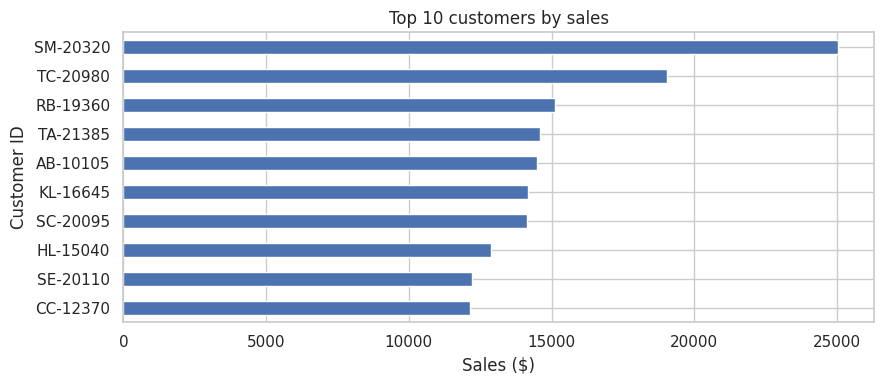

In [4]:
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
margin = 100*total_profit/total_sales if total_sales else np.nan
print(f"Sales: ${total_sales:,.2f} | Profit: ${total_profit:,.2f} | Margin: {margin:.1f}%")
if "order_id" in df:
    print(f"Orders: {df['order_id'].nunique():,} | Average order sales: ${total_sales/df['order_id'].nunique():,.2f}")
if "customer_id" in df:
    customer = df.groupby("customer_id").agg(sales=("sales","sum"), profit=("profit","sum"),
        line_items=("sales","size"), orders=("order_id","nunique") if "order_id" in df else ("sales","size"))
    customer = customer.sort_values("sales", ascending=False)
    display(customer.head(10))
    print(f"Top 10 customers' share of sales: {100*customer.head(10).sales.sum()/total_sales:.1f}%")
    fig, ax = plt.subplots(figsize=(9,4))
    customer.head(10).sales.sort_values().plot.barh(ax=ax)
    ax.set(title="Top 10 customers by sales", xlabel="Sales ($)", ylabel="Customer ID")
    plt.tight_layout(); plt.show()
else:
    print("Customer ID not available; customer-level purchase analysis skipped.")

## 4. Monthly revenue and seasonal patterns

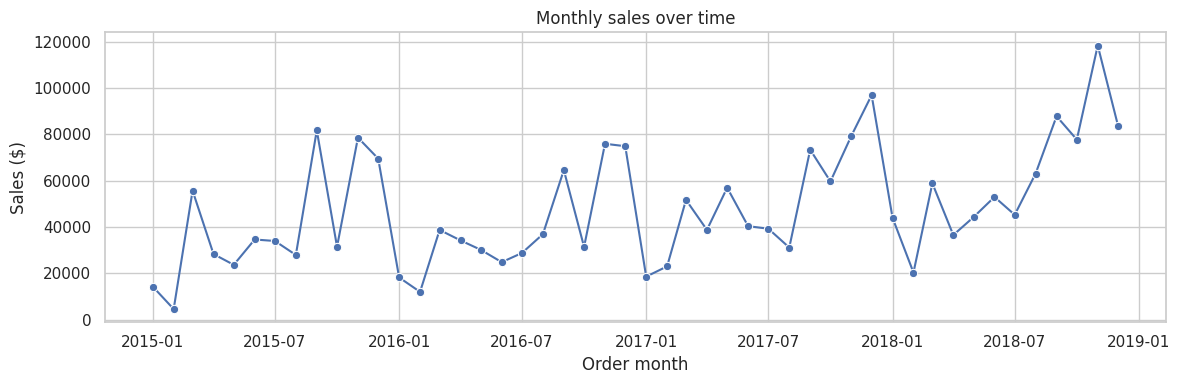

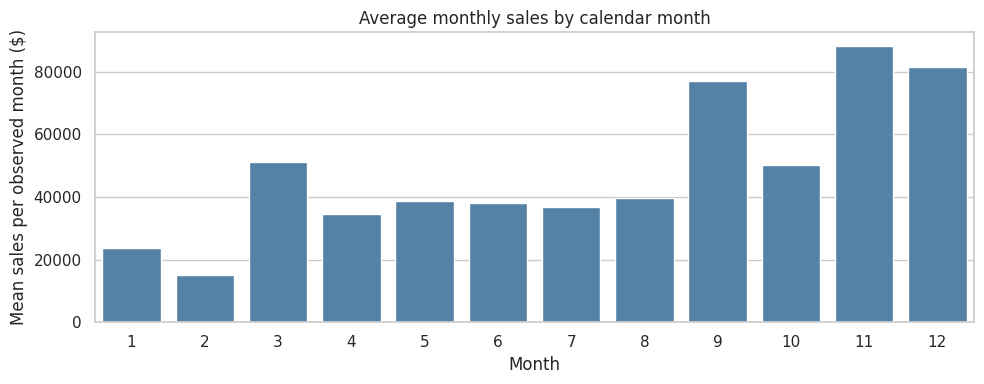

,sales,profit,lines
year_month,,,
2018-01-01,43971.3740,7140.4391,155
2018-02-01,20301.1334,1613.8720,107
2018-03-01,58872.3528,14751.8915,238
2018-04-01,36521.5361,933.2900,203
2018-05-01,44261.1102,6342.5828,242
2018-06-01,52981.7257,8223.3357,245
2018-07-01,45264.4160,6952.6212,226
2018-08-01,63120.8880,9040.9557,218
2018-09-01,87866.6520,10991.5556,459


In [5]:
monthly = df.groupby("year_month").agg(sales=("sales","sum"), profit=("profit","sum"), lines=("sales","size")).sort_index()
monthly.index = monthly.index.to_timestamp()
fig, ax = plt.subplots(figsize=(12,4))
sns.lineplot(data=monthly, x=monthly.index, y="sales", marker="o", ax=ax)
ax.set(title="Monthly sales over time", xlabel="Order month", ylabel="Sales ($)")
plt.tight_layout(); plt.show()
season = df.groupby("month").sales.sum().reindex(range(1,13),fill_value=0)
# Use mean sales per observed year-month, to avoid incomplete years dominating the chart
season_avg = monthly.assign(month=monthly.index.month).groupby("month").sales.mean().reindex(range(1,13))
fig, ax = plt.subplots(figsize=(10,4))
sns.barplot(color="steelblue", x=season_avg.index, y=season_avg.values, ax=ax)
ax.set(title="Average monthly sales by calendar month", xlabel="Month", ylabel="Mean sales per observed month ($)")
plt.tight_layout(); plt.show()
display(monthly.tail(12))

## 5. Category, region and customer segment

### Category performance

,sales,profit,transactions,margin_pct,sales_share_pct
category,,,,,
Technology,836154.03,145454.95,1847,17.40,36.4
Furniture,741999.80,18451.27,2121,2.49,32.3
Office Supplies,719047.03,122490.80,6026,17.04,31.3


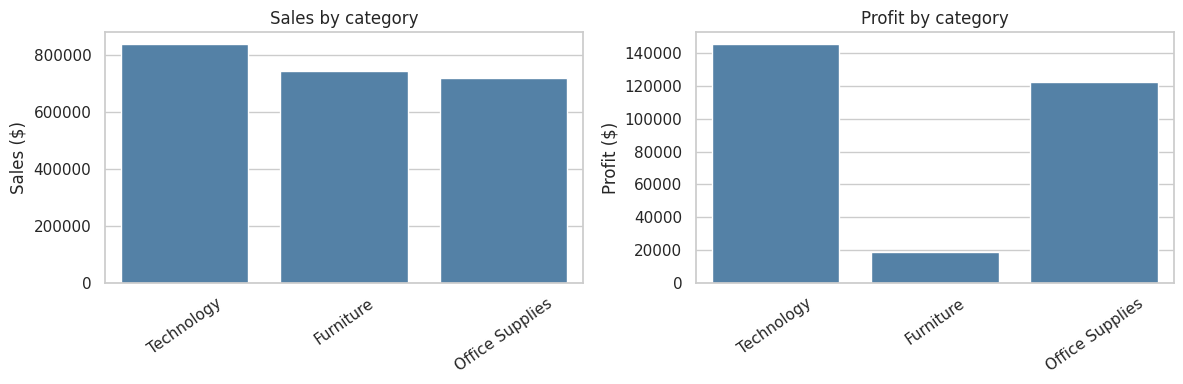

### Region performance

,sales,profit,transactions,margin_pct,sales_share_pct
region,,,,,
West,725457.82,108418.45,3203,14.94,31.58
East,678781.24,91522.78,2848,13.48,29.55
Central,501239.89,39706.36,2323,7.92,21.82
South,391721.90,46749.43,1620,11.93,17.05


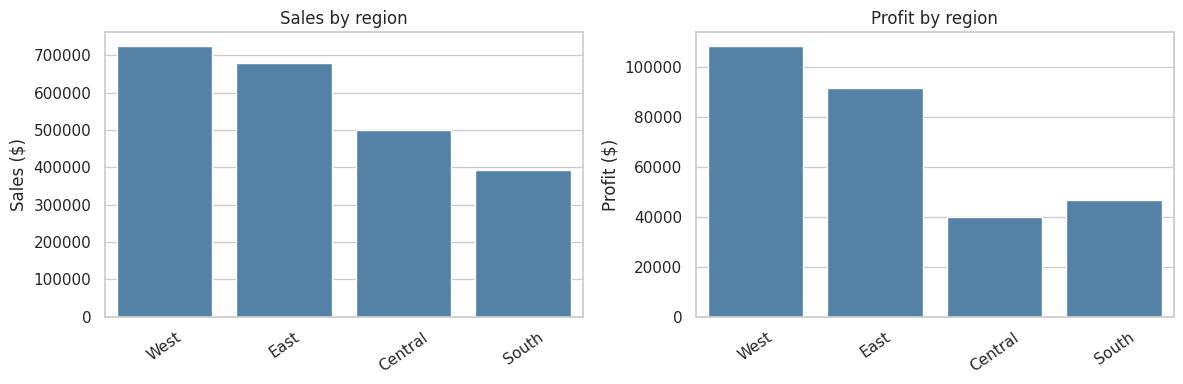

### Segment performance

,sales,profit,transactions,margin_pct,sales_share_pct
segment,,,,,
Consumer,1161401.34,134119.21,5191,11.55,50.56
Corporate,706146.37,91979.13,3020,13.03,30.74
Home Office,429653.15,60298.68,1783,14.03,18.70


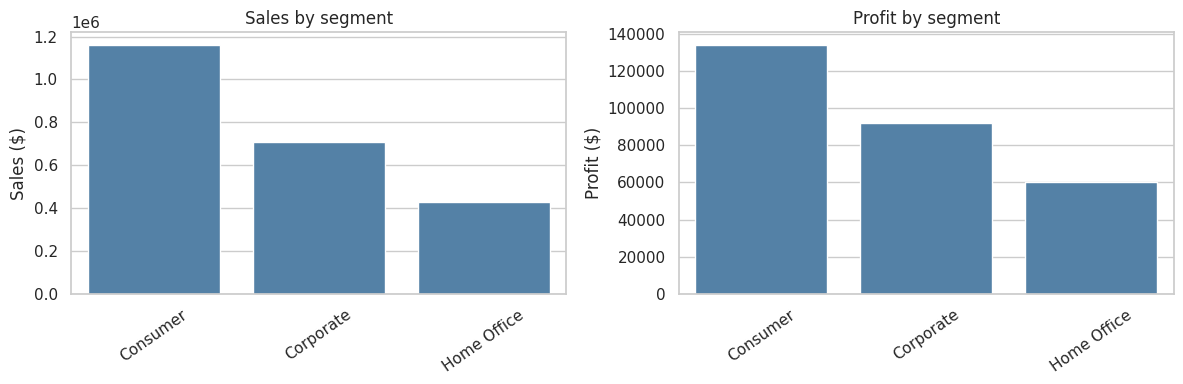

In [6]:
group_summaries = {}
for dimension in ["category", "region", "segment"]:
    summary = df.groupby(dimension, dropna=False).agg(sales=("sales","sum"), profit=("profit","sum"), transactions=("sales","size"))
    summary["margin_pct"] = 100*summary.profit/summary.sales.replace(0,np.nan)
    summary["sales_share_pct"] = 100*summary.sales/total_sales
    summary = summary.sort_values("sales", ascending=False)
    group_summaries[dimension] = summary
    display(Markdown(f"### {dimension.title()} performance")); display(summary.round(2))
    fig, axes = plt.subplots(1,2,figsize=(12,4))
    sns.barplot(color="steelblue", x=summary.index.astype(str), y=summary.sales, ax=axes[0])
    sns.barplot(color="steelblue", x=summary.index.astype(str), y=summary.profit, ax=axes[1])
    axes[0].set(title=f"Sales by {dimension}", xlabel="", ylabel="Sales ($)")
    axes[1].set(title=f"Profit by {dimension}", xlabel="", ylabel="Profit ($)")
    for ax in axes: ax.tick_params(axis="x",rotation=35)
    plt.tight_layout(); plt.show()

## 6. Discount sensitivity and loss exposure

,sales,profit,n,avg_profit,loss_rate,margin_pct
discount_band,,,,,,
0%,1087908.47,320987.60,4798,66.90,0.00,29.51
0–10%,54369.35,9029.18,94,96.06,4.26,16.61
10–20%,792152.89,91756.30,3709,24.74,13.99,11.58
20–30%,103226.66,-10369.28,227,-45.68,91.63,-10.05
30–40%,130911.24,-25448.19,233,-109.22,88.84,-19.44
40–50%,64403.51,-22999.54,77,-298.70,100.00,-35.71
>50%,64228.74,-76559.05,856,-89.44,100.00,-119.20


Line-item discount/profit Pearson correlation: -0.219


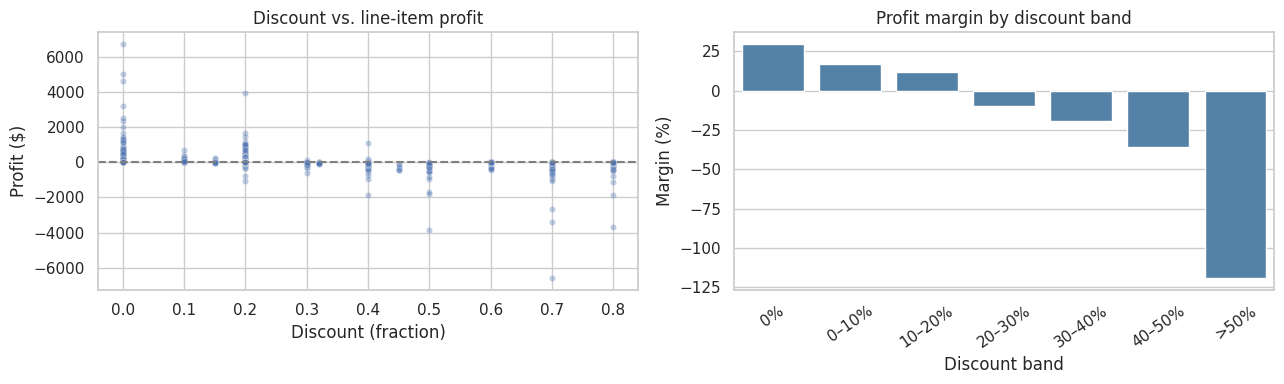

In [7]:
discount_df = df.dropna(subset=["discount"]).copy()
if discount_df.empty:
    print("No valid discount observations; discount analysis unavailable.")
else:
    discount_df["discount_band"] = pd.cut(discount_df.discount, bins=[-np.inf,0,.1,.2,.3,.4,.5,np.inf],
        labels=["0%","0–10%","10–20%","20–30%","30–40%","40–50%",">50%"], include_lowest=True)
    disc = discount_df.groupby("discount_band", observed=True).agg(
        sales=("sales","sum"),profit=("profit","sum"),n=("profit","size"),avg_profit=("profit","mean"),
        loss_rate=("profit",lambda x:100*(x<0).mean()))
    disc["margin_pct"] = 100*disc.profit/disc.sales.replace(0,np.nan)
    display(disc.round(2))
    corr = discount_df[["discount","profit"]].corr().iloc[0,1]
    print(f"Line-item discount/profit Pearson correlation: {corr:.3f}")
    fig, axes = plt.subplots(1,2,figsize=(13,4))
    sns.scatterplot(data=discount_df.sample(min(5000,len(discount_df)),random_state=42),
                    x="discount",y="profit",alpha=.35,s=20,ax=axes[0])
    axes[0].axhline(0,color="gray",ls="--"); axes[0].set(title="Discount vs. line-item profit",xlabel="Discount (fraction)",ylabel="Profit ($)")
    sns.barplot(color="steelblue", x=disc.index.astype(str),y=disc.margin_pct,ax=axes[1])
    axes[1].set(title="Profit margin by discount band",xlabel="Discount band",ylabel="Margin (%)")
    axes[1].tick_params(axis="x",rotation=35)
    plt.tight_layout(); plt.show()

## 7. Five annotated executive business findings (computed after running)
The following conclusions populate from the observed data. They distinguish descriptive findings from proposed actions; associations do not establish causality.

In [8]:
findings = []
if "customer_id" in df:
    top_share = 100*customer.head(10).sales.sum()/total_sales
    findings.append(("Customer concentration", f"The 10 highest-revenue customers contribute {top_share:.1f}% of total sales.",
                     "Evaluate retention and account management for valuable customers; avoid assuming revenue equals profitability."))
else:
    findings.append(("Customer purchase volume", "Customer IDs are absent; customer concentration cannot be quantified.",
                     "Collect a stable customer identifier before designing customer-level retention campaigns."))
if len(monthly):
    peak = season_avg.idxmax()
    findings.append(("Monthly seasonality", f"Calendar month {peak} has the highest mean monthly sales (${season_avg.max():,.0f}) among observed months.",
                     "Use this signal for inventory and staffing forecasts, while accounting for incomplete years and promotions."))
for dimension in ["category", "region", "segment"]:
    s = group_summaries[dimension]
    leader = s.index[0]
    findings.append((f"{dimension.title()} revenue mix",
                     f"{leader} leads {dimension} sales with ${s.iloc[0].sales:,.0f} ({s.iloc[0].sales_share_pct:.1f}% of total revenue); its profit margin is {s.iloc[0].margin_pct:.1f}%.",
                     "Compare revenue share with profit margin before reallocating commercial resources."))
if not discount_df.empty:
    findings.append(("Discount sensitivity",
                     f"Discount and line-item profit have a Pearson correlation of {corr:.2f}; the highest-discount band has a {disc.iloc[-1].loss_rate:.1f}% loss-making line-item rate (n={int(disc.iloc[-1].n):,}).",
                     "Review high-discount deals and their cost structure; validate patterns by category and region before changing policy."))
for i,(heading,evidence,action) in enumerate(findings,1):
    display(Markdown(f"**Finding {i} — {heading}.** {evidence}  \n**Business implication:** {action}"))

**Finding 1 — Customer concentration.** The 10 highest-revenue customers contribute 6.7% of total sales.  
**Business implication:** Evaluate retention and account management for valuable customers; avoid assuming revenue equals profitability.

**Finding 2 — Monthly seasonality.** Calendar month 11 has the highest mean monthly sales ($88,115) among observed months.  
**Business implication:** Use this signal for inventory and staffing forecasts, while accounting for incomplete years and promotions.

**Finding 3 — Category revenue mix.** Technology leads category sales with $836,154 (36.4% of total revenue); its profit margin is 17.4%.  
**Business implication:** Compare revenue share with profit margin before reallocating commercial resources.

**Finding 4 — Region revenue mix.** West leads region sales with $725,458 (31.6% of total revenue); its profit margin is 14.9%.  
**Business implication:** Compare revenue share with profit margin before reallocating commercial resources.

**Finding 5 — Segment revenue mix.** Consumer leads segment sales with $1,161,401 (50.6% of total revenue); its profit margin is 11.5%.  
**Business implication:** Compare revenue share with profit margin before reallocating commercial resources.

**Finding 6 — Discount sensitivity.** Discount and line-item profit have a Pearson correlation of -0.22; the highest-discount band has a 100.0% loss-making line-item rate (n=856).  
**Business implication:** Review high-discount deals and their cost structure; validate patterns by category and region before changing policy.

## 8. Interpretation limits and next steps
- Dataset rows may be **order lines**, not independent orders; use distinct `order_id` for order counts.
- Sales and profit are nominal and may span several years; this is descriptive EDA, not an inflation-adjusted analysis.
- Discounts are not randomly assigned. Product mix, order size, and region may confound the discount–profit relationship.
- Verify whether profit includes shipping, returns, and overhead before presenting it as net profit.
- Review negative sales, returns, outliers, and partial-year coverage before operational decisions.

**Optional export of cleaned dataset:**

In [9]:
df.to_csv("superstore_sales_cleaned.csv",index=False)
print("Saved superstore_sales_cleaned.csv")

Saved superstore_sales_cleaned.csv
